# Ensembles and chronological stacking

An **ensemble** combines several forecasts. Our previous SARIMA/weather blend used fixed 50/50 weights. **Stacking** learns a combination from earlier forecast errors.

The base models here are SARIMA, hour-specific weather Ridge, weather Ridge, last-day weather correction, and Chronos-Bolt Small. They represent different modeling assumptions and may make complementary errors.

| Method | What it does |
|---|---|
| `equal_mean` | Gives each base forecast 20% weight. |
| `median` | Takes the middle of the five forecasts each hour. |
| `stack_convex` | Learns nonnegative weights summing to one by minimizing earlier squared errors. |
| `stack_convex_recent4` | Learns those weights from only the latest four available forecast windows. |
| `stack_ridge` | Regularized linear stacking with an intercept; coefficients can be negative. |
| `stack_daywise` | Learns separate convex weights for forecast days one and two. |
| `stack_shrunk` | Mixes learned convex weights 50/50 with the existing fixed SARIMA/hour-weather blend. |

## Avoiding leakage
At window k, the meta-model sees only base forecasts and actual values from **earlier windows**. Base forecasts were themselves generated without seeing their future targets. We never train the stacker on predictions from the window it is being scored on. No random train/test split is used.

The first three windows warm up stacking; forward predictions for windows 3–5 start interval calibration. The same eleven selection windows (6–16) and previously seen audit (17) are used. After a window finishes, its actuals may train the next window's stacker. The final model uses all 18 completed historical windows.

Weather-stress stacking learns from the three earlier illustrative scenarios. They are repeated views of the same historical window, not independent windows. Future point forecasts use the actual supplied future-weather forecast without adding random noise.

**Intervals differ from earlier candidates:** the new ensembles use an expanding collection of earlier forward forecast errors, separately by forecast day. Previous model intervals retain their original fixed-calibration evaluation. Thus a Winkler difference reflects both the model and interval-calibration policy. Coverage is not guaranteed.

All choices remain exploratory because the base models and methods were proposed after seeing prior results. Correct chronological stacking avoids direct leakage but does not remove model-selection optimism. Hidden-leaderboard success cannot be guaranteed.

Reproduce with `.venv/bin/python session1_stacking.py`; earlier `results_hf/` and `results_robust/` artifacts are required.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
out=Path("results_stacking")
report=json.loads((out/"run_summary.json").read_text())
summary=pd.read_csv(out/"model_comparison.csv")
windows=pd.read_csv(out/"window_comparison.csv",parse_dates=["start","end"])
consistency=pd.read_csv(out/"window_consistency.csv")
weights=json.loads((out/"weights_by_window.json").read_text())
SCENARIO="weather_stress"
winner=report["selected_model"];best=report["best_new_ensemble"]
focus=report["methods"]+["seasonal_naive","SARIMA_21d","blend_SARIMA50_hour50"]
selection=summary[(summary.phase=="selection")&(summary.scenario==SCENARIO)&summary.model.isin(focus)]
print("Overall selected:",winner,"\nBest new ensemble:",best)
display(selection.set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))
print("Window wins (baseline ties itself)")
display(consistency[(consistency.scenario==SCENARIO)&consistency.model.isin(focus)].set_index("model").drop(columns="scenario").round(3))


Overall selected: equal_mean 
Best new ensemble: equal_mean


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
equal_mean,265.861,0.836,353.880,1188.786,0.946
median,271.779,0.854,378.170,1243.566,0.946
stack_shrunk,272.671,0.857,335.380,1220.388,0.941
stack_daywise,275.066,0.865,280.086,1240.632,0.942
stack_convex_recent4,275.482,0.866,363.029,1235.603,0.939
stack_ridge,275.884,0.867,356.298,1202.273,0.949
stack_convex,276.375,0.869,316.914,1243.623,0.936
blend_SARIMA50_hour50,277.105,0.871,355.026,1422.269,0.888
seasonal_naive,318.144,1.000,392.611,2258.119,0.771


Window wins (baseline ties itself)


,windows,wins,mean_RMSE,median_RMSE_ratio,best_RMSE_ratio,worst_RMSE_ratio,mean_rank,win_rate
model,,,,,,,,
equal_mean,11,9,259.136,0.877,0.602,1.203,10.000,0.818
median,11,9,265.136,0.869,0.624,1.280,12.091,0.818
blend_SARIMA50_hour50,11,8,267.492,0.922,0.582,1.137,11.727,0.727
stack_shrunk,11,7,265.478,0.885,0.596,1.347,11.636,0.636
stack_ridge,11,7,270.338,0.892,0.623,1.479,13.545,0.636
stack_convex,11,7,270.170,0.775,0.600,1.580,14.364,0.636
stack_convex_recent4,11,7,268.650,0.801,0.607,1.390,14.364,0.636
stack_daywise,11,7,268.760,0.809,0.561,1.622,14.545,0.636
SARIMA_21d,11,7,309.648,0.972,0.833,1.257,24.545,0.636


## Which windows improve?
Below 1 beats seasonal naive. The final audit column is excluded from selection and win counts.

label,Oct 03,Oct 05,Oct 07,Oct 09,Oct 11,Oct 13,Oct 15,Oct 17,Oct 19,Oct 21,Oct 23,Oct 25 [audit]
model,,,,,,,,,,,,
equal_mean,0.91,0.99,0.76,0.88,0.60,1.05,0.75,0.66,0.72,1.00,1.20,1.43
median,1.00,0.99,0.76,0.87,0.62,1.08,0.75,0.64,0.84,0.91,1.28,1.52
stack_shrunk,0.89,1.03,0.83,0.92,0.60,1.04,0.75,0.62,0.71,1.08,1.35,1.49
stack_daywise,0.91,1.04,0.81,0.77,0.74,1.11,0.75,0.56,0.68,1.12,1.62,1.69
stack_convex_recent4,0.93,1.06,0.78,0.77,0.64,1.11,0.79,0.61,0.80,1.09,1.39,1.25
stack_ridge,0.91,1.03,0.76,0.89,0.64,1.11,0.72,0.62,0.78,1.16,1.48,1.57
stack_convex,0.89,1.05,0.77,0.77,0.67,1.11,0.77,0.60,0.74,1.18,1.58,1.65
blend_SARIMA50_hour50,0.89,1.02,0.92,1.08,0.58,0.99,0.75,0.65,0.70,1.00,1.14,1.35
seasonal_naive,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


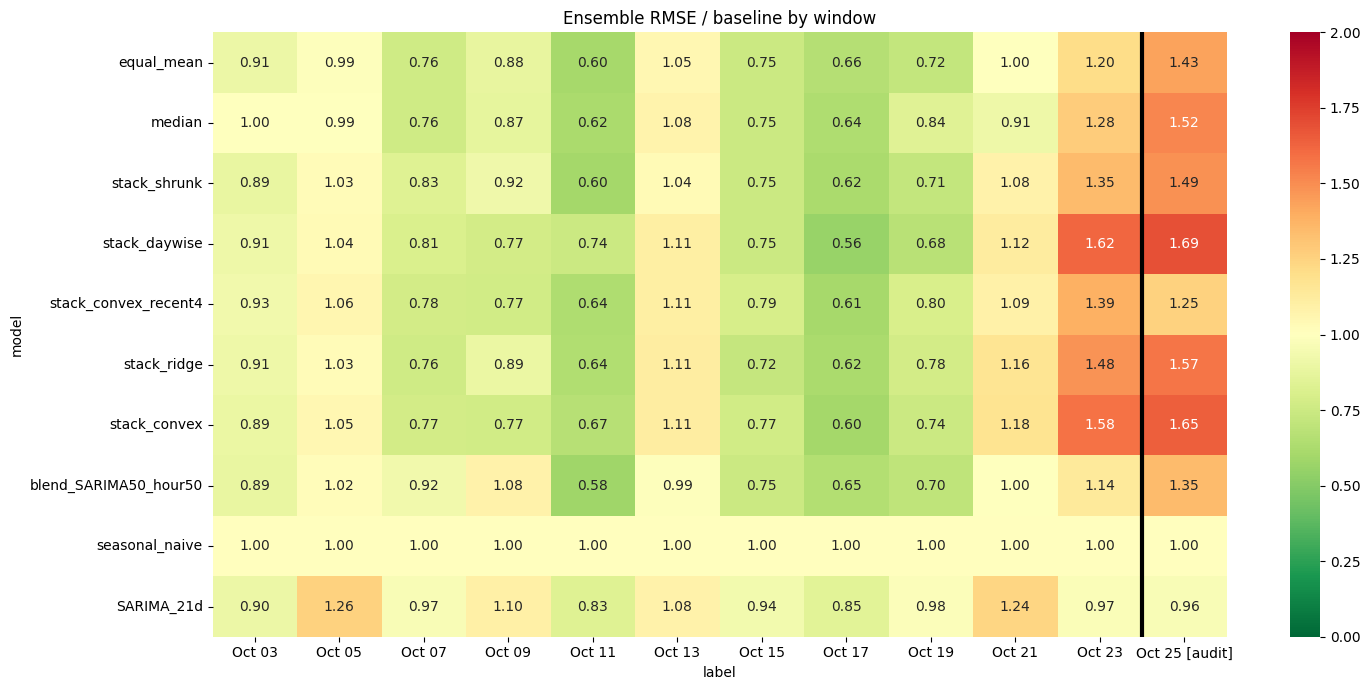

In [2]:
w=windows[(windows.scenario==SCENARIO)&windows.model.isin(focus)].copy()
w["label"]=w.start.dt.strftime("%b %d")+np.where(w.phase.eq("selection"),""," [audit]")
labels=w.sort_values("start").label.drop_duplicates().tolist()
ratios=w.pivot(index="model",columns="label",values="RMSE_ratio").reindex(index=selection.model,columns=labels)
display(ratios.round(2))
fig,ax=plt.subplots(figsize=(15,7))
sns.heatmap(ratios,annot=True,fmt=".2f",cmap="RdYlGn_r",center=1,vmin=0,vmax=max(2,float(ratios.max().max())),ax=ax)
ax.axvline(11,color="black",lw=3);ax.set_title("Ensemble RMSE / baseline by window")
plt.tight_layout();fig.savefig(out/"window_comparison.png",dpi=150,bbox_inches="tight");plt.show()


## Learned weights
These weights come only from earlier available forecast errors. A zero means the optimizer did not need that base model in this combination. Ridge coefficients are not constrained percentages.

stack_convex — final refit


,value
weights.SARIMA_21d,0.092714
weights.hour_weather_ridge_14d,0.143944
weights.weather_ridge_21d,0.100114
weights.weather_correction_28d,0.285986
weights.chronos_bolt_small_504h,0.377241


stack_convex_recent4 — final refit


,value
weights.SARIMA_21d,4.370278e-01
weights.hour_weather_ridge_14d,0.000000e+00
weights.weather_ridge_21d,0.000000e+00
weights.weather_correction_28d,5.629722e-01
weights.chronos_bolt_small_504h,4.336809e-18


stack_daywise — final refit


,value
day1.SARIMA_21d,0.085117
day1.hour_weather_ridge_14d,0.000000
day1.weather_ridge_21d,0.004824
day1.weather_correction_28d,0.373572
day1.chronos_bolt_small_504h,0.536488
day2.SARIMA_21d,0.130699
day2.hour_weather_ridge_14d,0.291232
day2.weather_ridge_21d,0.232869
day2.weather_correction_28d,0.170457
day2.chronos_bolt_small_504h,0.174743


stack_shrunk — final refit


,value
weights.SARIMA_21d,0.296357
weights.hour_weather_ridge_14d,0.321972
weights.weather_ridge_21d,0.050057
weights.weather_correction_28d,0.142993
weights.chronos_bolt_small_504h,0.188621


stack_ridge — final refit


,value
intercept,-15.581214
coefficients.SARIMA_21d,0.162855
coefficients.hour_weather_ridge_14d,0.184849
coefficients.weather_ridge_21d,0.171300
coefficients.weather_correction_28d,0.226849
coefficients.chronos_bolt_small_504h,0.272063


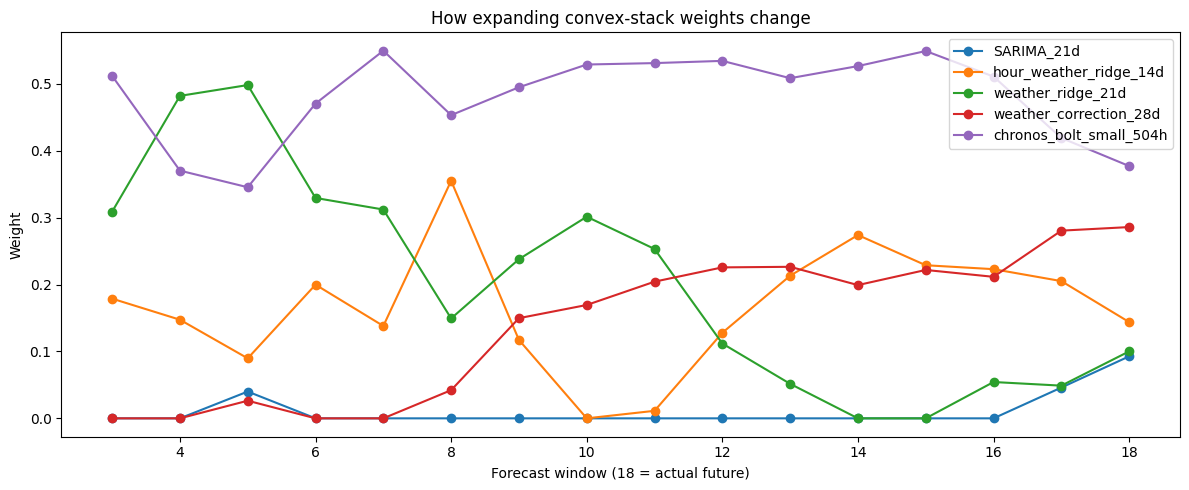

In [3]:
for method in ["stack_convex","stack_convex_recent4","stack_daywise","stack_shrunk","stack_ridge"]:
    entry=next(r for r in weights if r["model"]==method and r["scenario"]==SCENARIO and r["fold"]==18)
    print(method, "— final refit")
    display(pd.json_normalize(entry["details"]).T.rename(columns={0:"value"}))
rows=[]
for item in weights:
    if item["model"]=="stack_convex" and item["scenario"]==SCENARIO:
        rows.append({"fold":item["fold"],**item["details"]["weights"]})
ax=pd.DataFrame(rows).set_index("fold").plot(figsize=(12,5),marker="o")
ax.set_ylabel("Weight");ax.set_xlabel("Forecast window (18 = actual future)")
ax.set_title("How expanding convex-stack weights change")
plt.tight_layout();plt.show()


## Previously seen audit and actual future forecast

,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
SARIMA_21d,116.108,0.964,38.789,904.063,1.000
seasonal_naive,120.404,1.000,51.088,568.464,1.000
stack_convex_recent4,150.571,1.251,58.711,843.271,1.000
blend_SARIMA50_hour50,162.473,1.349,50.306,716.054,0.993
equal_mean,172.215,1.430,60.560,808.858,1.000
stack_shrunk,178.810,1.485,56.704,837.305,1.000
median,183.177,1.521,63.784,798.349,0.986
stack_ridge,189.542,1.574,60.354,836.854,0.993
stack_convex,198.405,1.648,64.211,875.383,0.993


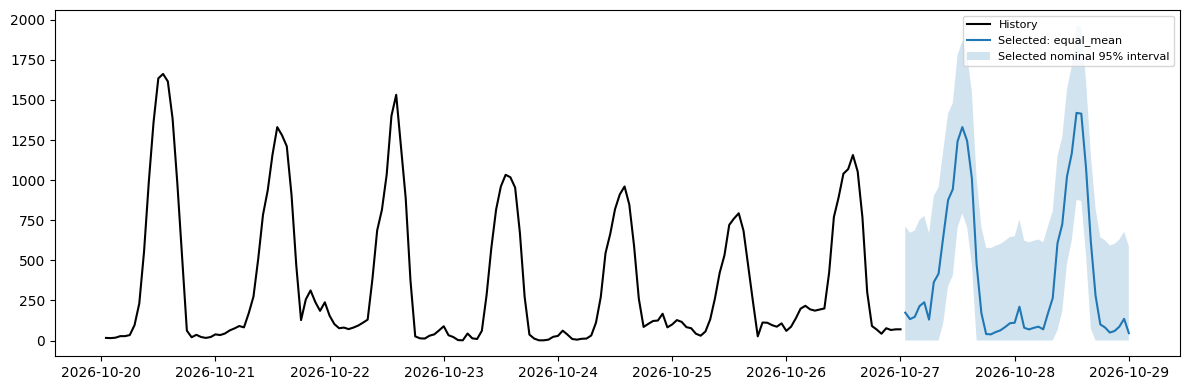

In [4]:
audit=summary[(summary.phase=="last_window_audit")&(summary.scenario==SCENARIO)&summary.model.isin(focus)]
display(audit.set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))
data=pd.read_csv("train.csv",parse_dates=["ds"])
sub=pd.read_csv(out/"selected_model_forecast.csv",parse_dates=["ds"])
new=pd.read_csv(out/"best_new_ensemble_forecast.csv",parse_dates=["ds"])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(data.ds.iloc[-168:],data.y.iloc[-168:],label="History",color="black")
ax.plot(sub.ds,sub.forecast,label=f"Selected: {winner}")
if winner!=best:ax.plot(new.ds,new.forecast,label=f"Best new ensemble: {best}",linestyle="--")
ax.fill_between(sub.ds,sub.lower_95,sub.upper_95,alpha=.2,label="Selected nominal 95% interval")
ax.legend(fontsize=8);plt.tight_layout();fig.savefig(out/"forecast.png",dpi=150,bbox_inches="tight");plt.show()


## Save the overall selected forecast
The file already exists in `results_stacking/selected_model_forecast.csv`. Set your surname to create the Moodle filename. No upload is performed.

In [5]:
SURNAME=""
if SURNAME.strip():
    assert not any(c in SURNAME for c in "/\\")
    filename=f"{SURNAME.strip().upper()}_project.csv"
    pd.read_csv(out/"selected_model_forecast.csv").to_csv(filename,index=False)
    print("Saved",filename)
else:
    print("Set SURNAME to create the required Moodle filename.")


Set SURNAME to create the required Moodle filename.
